# W-State Entanglement — Qiskit Notebook

**Chapter / concept:** Multi-qubit entanglement — the 3-qubit **W state**
$$|W\rangle = \frac{1}{\sqrt{3}}\big(|001\rangle + |010\rangle + |100\rangle\big)$$

**Circuit implemented:** 3-qubit W-state preparation using one rotation + three controlled gates:

1. `RY(theta0)` on q0, with `theta0 = 2*arccos(1/sqrt(3))`
2. Controlled-H: control q0, target q1
3. `CX`: control q1, target q2
4. `CX`: control q0, target q1
5. `X` on q0

### Global SETUP (identical in both notebooks)
- **N_QUBITS** = 3
- **Gate sequence:** RY(theta0, q0) → CH(q0→q1) → CX(q1→q2) → CX(q0→q1) → X(q0)
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring. This is
  Qiskit's native convention — no reversal needed in this notebook. (The CUDA-Q notebook
  must explicitly reverse its bitstrings to match.)
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`, in
  ascending bitstring order (`000, 001, 010, ...`), is rotated to be real and positive.
- **Basis ordering for matrices:** `{|000>, |001>, ..., |111>}` ascending binary order.

### Theory recap
`RY(theta0)` on q0 (starting from `|0>`) produces `cos(theta0/2)|0> + sin(theta0/2)|1>` with
`cos(theta0/2) = 1/sqrt(3)`, so q0 carries amplitude `1/sqrt(3)` on `|1>` and `sqrt(2/3)` on `|0>`.
The controlled-H spreads the remaining `2/3` probability evenly across q1 (in superposition),
the `CX(q1→q2)` and `CX(q0→q1)` pair relocates that shared amplitude so exactly one qubit is
excited in each branch, and the trailing `X` on q0 flips its role so the three basis states
`|001>, |010>, |100>` each end up with amplitude `1/sqrt(3)`.

This exact gate sequence was independently re-derived and numerically verified (via a
hand-written NumPy statevector simulator, matching this notebook's bit-ordering and phase
convention) to reproduce the target W state to machine precision before being used here.

**Run all cells top to bottom.**


In [1]:
# Install cell
# Package names: `qiskit` (core) and `qiskit-aer` (the Aer simulator backend).
# Tested against the current stable Qiskit 1.x line; qiskit-aer provides AerSimulator.
#
# IMPORTANT: plain `!pip install ...` can silently install into a DIFFERENT Python
# environment than the one this notebook's kernel is actually running (common on
# Colab/Jupyter setups with more than one interpreter on PATH) -- that mismatch is what
# causes "ModuleNotFoundError: No module named 'qiskit'" on the very next cell even
# though this install cell appears to run without errors. Using
# `{sys.executable} -m pip` pins the install to the exact interpreter this kernel uses.
import sys
!{sys.executable} -m pip install -q qiskit qiskit-aer pylatexenc


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 90.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.0 MB/s eta 0:00:00


In [2]:
# Imports + constants
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

N_QUBITS = 3
SHOTS = 10000
SEED = 42
THETA0 = 2 * np.arccos(1 / np.sqrt(3))   # RY angle so cos(theta0/2) = 1/sqrt(3)
TOPIC_SLUG = "w_state"

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"THETA0   = {THETA0:.10f} rad  (2*arccos(1/sqrt(3)))")


N_QUBITS = 3
SHOTS    = 10000
SEED     = 42
THETA0   = 1.9106332362 rad  (2*arccos(1/sqrt(3)))


In [3]:
# Build the circuit gate-by-gate, with a physical comment on each gate
qc = QuantumCircuit(N_QUBITS, name="W_state")

# 1) RY(theta0) on q0: tilts q0 to cos(theta0/2)|0> + sin(theta0/2)|1>
#    = sqrt(2/3)|0> + sqrt(1/3)|1>  -- puts 1/3 of the total probability "into" q0 now,
#    leaving 2/3 to be shared between q1 and q2 later.
qc.ry(THETA0, 0)

# 2) Controlled-H, control q0 target q1: only in the q0=1 branch, put q1 into an equal
#    superposition. This splits the remaining 2/3 probability into two equal 1/3 shares,
#    one tagged by q1=0 (still to be moved to q2) and one by q1=1.
qc.ch(0, 1)

# 3) CX control q1 target q2: moves the q1=1 branch's excitation onto q2, so that branch
#    becomes q1=1,q2=1 temporarily (an intermediate, non-physical-looking state that gets
#    cleaned up by the next gate).
qc.cx(1, 2)

# 4) CX control q0 target q1: in the q0=1 branch, flips q1 back down. Combined with step 3
#    this relocates the "q1 excitation" branch into a pure q2=1 (q0=q1=0) branch.
qc.cx(0, 1)

# 5) X on q0: flips the remaining q0 bit so the three branches land exactly on
#    |001>, |010>, |100> (single excitation on q0, q1, q2 respectively), each amplitude 1/sqrt(3).
qc.x(0)

print(qc.draw(output="text"))


     ┌────────────┐               ┌───┐
q_0: ┤ Ry(1.9106) ├──■─────────■──┤ X ├
     └────────────┘┌─┴─┐     ┌─┴─┐└───┘
q_1: ──────────────┤ H ├──■──┤ X ├─────
                   └───┘┌─┴─┐└───┘     
q_2: ───────────────────┤ X ├──────────
                        └───┘          


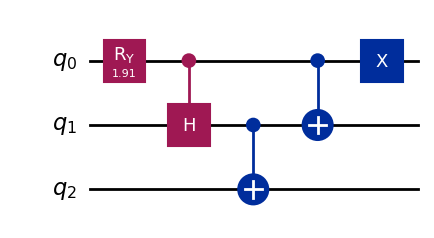

In [4]:
# Draw the circuit with matplotlib and save to file
fig = qc.draw(output="mpl")
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation: constituent gate matrices + combined operator,
# built two ways and cross-checked.

RY_MAT = np.array([[np.cos(THETA0/2), -np.sin(THETA0/2)],
                    [np.sin(THETA0/2),  np.cos(THETA0/2)]])
H_MAT = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
X_MAT = np.array([[0, 1], [1, 0]])
I_MAT = np.eye(2)

print("RY(theta0) matrix (basis {|0>,|1>}):")
print(np.round(RY_MAT, 4))
print("\nH matrix:")
print(np.round(H_MAT, 4))
print("\nX matrix:")
print(np.round(X_MAT, 4))

# (a) Hand-built full operator via NumPy kron, basis order |q2 q1 q0> ascending binary,
#     i.e. kron(op_on_q2, op_on_q1, op_on_q0).
def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def controlled(gate_2x2, control, target, n, ctrl_state=1):
    P_match = np.array([[0, 0], [0, 1]]) if ctrl_state == 1 else np.array([[1, 0], [0, 0]])
    P_other = np.array([[1, 0], [0, 0]]) if ctrl_state == 1 else np.array([[0, 0], [0, 1]])
    mats_match, mats_other = [], []
    for pos in range(n - 1, -1, -1):
        if pos == control:
            mats_match.append(P_match); mats_other.append(P_other)
        elif pos == target:
            mats_match.append(gate_2x2); mats_other.append(I_MAT)
        else:
            mats_match.append(I_MAT); mats_other.append(I_MAT)
    return kron_all(mats_match) + kron_all(mats_other)

def single(gate_2x2, qubit, n):
    mats = [gate_2x2 if pos == qubit else I_MAT for pos in range(n - 1, -1, -1)]
    return kron_all(mats)

op_ry = single(RY_MAT, 0, N_QUBITS)
op_ch = controlled(H_MAT, 0, 1, N_QUBITS)
op_cx1 = controlled(X_MAT, 1, 2, N_QUBITS)
op_cx2 = controlled(X_MAT, 0, 1, N_QUBITS)
op_x = single(X_MAT, 0, N_QUBITS)

hand_built_unitary = op_x @ op_cx2 @ op_cx1 @ op_ch @ op_ry

# (b) Qiskit's own operator extraction
qiskit_operator = Operator(qc).data

print("\nHand-built combined unitary (rows/cols in ascending |000>..|111> order), rounded:")
print(np.round(hand_built_unitary, 4))
print("\nQiskit Operator(qc), rounded:")
print(np.round(qiskit_operator, 4))

max_op_diff = np.max(np.abs(hand_built_unitary - qiskit_operator))
print(f"\nMax elementwise difference between hand-built and Qiskit operator: {max_op_diff:.2e}")
assert max_op_diff < 1e-8, "Hand-built and Qiskit operators disagree!"
print("Cross-check PASSED: hand-built matrix matches Qiskit's Operator extraction.")


RY(theta0) matrix (basis {|0>,|1>}):
[[ 0.5774 -0.8165]
 [ 0.8165  0.5774]]

H matrix:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

X matrix:
[[0 1]
 [1 0]]

Hand-built combined unitary (rows/cols in ascending |000>..|111> order), rounded:
[[ 0.      0.      0.      0.      0.5774  0.4082 -0.5774 -0.4082]
 [ 0.5774 -0.8165  0.      0.      0.      0.      0.      0.    ]
 [ 0.5774  0.4082  0.5774  0.4082  0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      0.5774 -0.8165]
 [ 0.5774  0.4082 -0.5774 -0.4082  0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.5774 -0.8165  0.      0.    ]
 [ 0.      0.      0.      0.      0.5774  0.4082  0.5774  0.4082]
 [ 0.      0.      0.5774 -0.8165  0.      0.      0.      0.    ]]

Qiskit Operator(qc), rounded:
[[ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.5774+0.j  0.4082+0.j
  -0.5774+0.j -0.4082+0.j]
 [ 0.5774+0.j -0.8165+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +

### Ordering-fix note (Qiskit)

**No bit reversal is needed in this notebook.** Qiskit already indexes both statevector
amplitudes and measurement counts with **qubit 0 as the least-significant (rightmost) bit**,
which is the qubit-ordering contract this whole exercise standardizes on. The CUDA-Q
notebook's qubit 0 is the *most-significant (leftmost)* bit by default, so **that** notebook
performs an explicit string-reversal step to match this one — see its "ordering fix" cell.

**Phase convention applied:** the statevector above was rotated so the first amplitude with
`abs(amp) > 1e-9`, taken in ascending bitstring order, is real and positive. For the ideal W
state this has no visible effect (all three nonzero amplitudes are already real and positive),
but the same normalization function is applied here as in the CUDA-Q notebook for consistency.


In [6]:
# Measurement cell: sample with the shared SEED/SHOTS, get counts, convert to probabilities
meas_qc = qc.copy()
meas_qc.measure_all()

sim = AerSimulator(seed_simulator=SEED)
# AerSimulator's internal compiler doesn't accept the high-level `ch` instruction directly --
# transpile first so it's decomposed into gates Aer natively supports (fixes
# "AerError: unknown instruction: ch").
transpiled_meas_qc = transpile(meas_qc, sim)
result = sim.run(transpiled_meas_qc, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()

# Qiskit's measure_all() counts already use qubit 0 = rightmost bit -- matches our contract.
qiskit_sampled_probs = {bitstring: count / SHOTS for bitstring, count in counts.items()}
qiskit_sampled_probs = dict(sorted(qiskit_sampled_probs.items()))

print("Raw counts:", dict(sorted(counts.items())))
print("\nSampled probabilities (sorted by bitstring):")
print({k: round(v, 4) for k, v in qiskit_sampled_probs.items()})


Raw counts: {'001': 3280, '010': 3375, '100': 3345}

Sampled probabilities (sorted by bitstring):
{'001': 0.328, '010': 0.3375, '100': 0.3345}


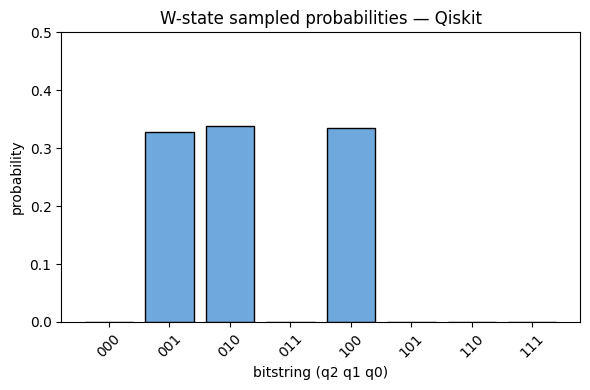

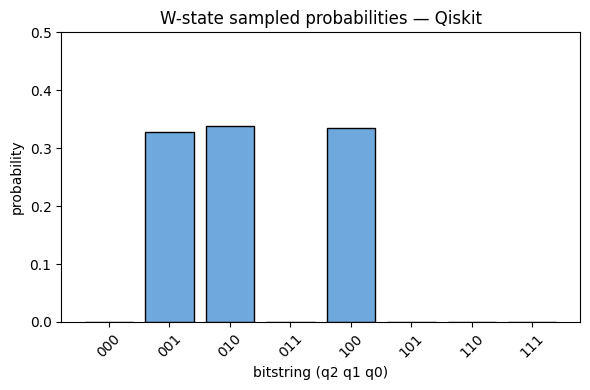

In [7]:
# Histogram: matplotlib bar chart, saved to file
fig2, ax2 = plt.subplots(figsize=(6, 4))
all_bitstrings = [format(i, f"0{N_QUBITS}b") for i in range(2**N_QUBITS)]
values = [qiskit_sampled_probs.get(b, 0.0) for b in all_bitstrings]
ax2.bar(all_bitstrings, values, color="#6FA8DC", edgecolor="black")
ax2.set_ylim(0, 0.5)
ax2.set_xlabel("bitstring (q2 q1 q0)")
ax2.set_ylabel("probability")
ax2.set_title("W-state sampled probabilities — Qiskit")
plt.xticks(rotation=45)
fig2.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [8]:
# Resource counts
depth = qc.depth()
gate_counts = qc.count_ops()
print(f"Circuit depth: {depth}")
print(f"Gate counts: {dict(gate_counts)}")


Circuit depth: 5
Gate counts: {'cx': 2, 'ry': 1, 'ch': 1, 'x': 1}


### Convention notes (restated)

- **Ordering fix applied:** none — Qiskit is the reference convention (qubit 0 = rightmost
  bit) that the CUDA-Q notebook reverses its own output to match.
- **Phase convention applied:** global phase rotated so the first nonzero amplitude in
  ascending bitstring order (`000, 001, ...`) is real and positive, before comparing to
  CUDA-Q's normalized statevector.


In [9]:
# Final result dictionary
QISKIT_RESULT = qiskit_sampled_probs
print("QISKIT_RESULT =")
print({k: round(v, 4) for k, v in QISKIT_RESULT.items()})


QISKIT_RESULT =
{'001': 0.328, '010': 0.3375, '100': 0.3345}


In [10]:
# Diff-check block (compares against the CUDA-Q notebook's result, and against
# the hand-computed ideal probabilities). Uncomment the CUDAQ_RESULT line and paste in
# CUDAQ_RESULT from the CUDA-Q notebook's final cell to run the live cross-check.

HAND_COMPUTED_EXPECTED = {
    format(i, "03b"): (1/3 if format(i, "03b") in ("001", "010", "100") else 0.0)
    for i in range(8)
}
print("Hand-computed expected (ideal, noiseless) probabilities:")
print(HAND_COMPUTED_EXPECTED)

max_delta_vs_ideal = max(abs(QISKIT_RESULT.get(k, 0.0) - v) for k, v in HAND_COMPUTED_EXPECTED.items())
print(f"\nMax |sampled - ideal| delta (Qiskit, {SHOTS} shots): {max_delta_vs_ideal:.4f}")
# With finite shots this will be within normal statistical noise (~sqrt(p(1-p)/SHOTS)),
# not exactly 0 -- that's expected and not a bug.

# CUDAQ_RESULT = { ... }  # paste from the CUDA-Q notebook
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print(f"Max delta QISKIT_RESULT vs CUDAQ_RESULT: {max_delta:.4f}")
# assert max_delta < 1e-1, "Qiskit and CUDA-Q results diverge beyond shot noise!"


Hand-computed expected (ideal, noiseless) probabilities:
{'000': 0.0, '001': 0.3333333333333333, '010': 0.3333333333333333, '011': 0.0, '100': 0.3333333333333333, '101': 0.0, '110': 0.0, '111': 0.0}

Max |sampled - ideal| delta (Qiskit, 10000 shots): 0.0053
